# ML-10 — Content Action Playbook

**Davidson C. Briones · FlyRank ML Internship · Week 7**

[Open in Colab](https://colab.research.google.com/github/Davidsoooooon/ML-Intern---Briones/blob/main/work/notebooks/w07_action_playbook.ipynb)

This notebook turns the March validation audit into a **historical, human-reviewed editorial
queue**. It follows `skills/README.md`, `writing-honest-claims`, and `flyrank/flyrank-data`.
The model flags a later impression-decline proxy; it does not establish that a page needs a
refresh or that an edit would improve traffic.

**Run:** in Colab, enable notebook access to the existing read-only `HF_TOKEN` secret, then
select **Runtime → Run all**. Locally, use the same environment variable, an approved Hub
cache, or `FLYRANK_MARCH_PARQUET` pointing to the approved March file. Never paste a token into
a cell. The first data run repeats the audited nested selection; later runs reuse a verified
local predictions cache. Only one March partition is downloaded, not the entire warehouse.

**Execution status is reported in section 6.** Without approved data, the notebook still
extracts the saved audit receipts and prepares the writing and figure, but does **not** invent
a page queue or mark the assignment complete. The bundled starter CSV is not a substitute for
the validated warehouse cohort. Prepared with AI assistance; review the final outputs yourself.


## 1. Ranked actions + reason codes

The validated design supplies **five separate queues of 50 held-out pages**, one per outer
fold. I preserve their within-fold ranks. Scores from different fitted models are not pooled
into a new global top 50. These queues replay a decision on **15 March 2026** using features
from March 1–14; March 15–28 outcomes are used only for retrospective evaluation.

The order comes from the selected model's score, with stable pseudonymous-key order breaking
ties. The action mapping is a new, transparent editorial policy; its usefulness has not been
validated. Reason codes describe observable conditions, **not causal explanations or model
feature attributions**. Data holds stay at their original rank and are not silently replaced.


In [1]:
import importlib.util
import subprocess
import sys

packages = {'numpy': 'numpy>=1.26', 'pandas': 'pandas>=2.2', 'sklearn': 'scikit-learn>=1.4',
            'duckdb': 'duckdb>=1.0', 'huggingface_hub': 'huggingface_hub>=0.24',
            'pyarrow': 'pyarrow', 'matplotlib': 'matplotlib>=3.8', 'lxml': 'lxml', 'IPython': 'ipython'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import io
import os
import platform
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import duckdb
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from huggingface_hub import hf_hub_download, get_token
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

REPO_URL = 'https://github.com/Davidsoooooon/ML-Intern---Briones.git'
root_candidates = [Path.cwd(), *Path.cwd().parents, Path('/content/ML-Intern---Briones')]
ROOT = next((p for p in root_candidates if (p / 'work/notebooks/w06_validation_audit.ipynb').is_file()), None)
if ROOT is None:
    ROOT = Path('/content/ML-Intern---Briones') if Path('/content').is_dir() else Path.cwd() / 'ML-Intern---Briones'
    if ROOT.exists():
        raise RuntimeError('The destination exists but is not the expected repository. Open the correct checkout.')
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(ROOT)], check=True, capture_output=True)
OUT, FIG = ROOT / 'work/outputs', ROOT / 'work/figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FEATURES = ['impressions_early', 'avg_position_early', 'position_volatility_early', 'active_days_early']
KEYS = ['client_hash_id', 'content_hash_id']
TARGET = 'is_declining_proxy'
CONFIG = {
    'pipeline_version': 'w07-action-playbook-v1', 'seed': 42, 'outer_folds': 5, 'inner_folds': 3,
    'queue_size_per_fold': 50, 'dataset': 'FlyRank/internship-warehouse',
    'revision': '50cbf7c3909d07be4d1b5906b4d09e882e5acbf2',
    'partition': 'fact_content_daily_performance/month=2026-03/data_0.parquet',
    'partition_sha256': '6ebd367f05932238df05b193f9cfb9cc7839d7856b65ef74b5a122d5fadef589',
    'feature_start': '2026-03-01', 'feature_end': '2026-03-14',
    'decision_date': '2026-03-15', 'label_end': '2026-03-28',
    'min_early_impressions': 100, 'decline_ratio': 0.8,
    'review_minutes_assumed': 15,
}
ENV = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
       'sklearn': sklearn.__version__, 'duckdb': duckdb.__version__}
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

cache_key = hashlib.sha256(json.dumps({'config': CONFIG, 'environment': ENV}, sort_keys=True).encode()).hexdigest()
STATE = {'approved_data': False, 'ranked_queue': False, 'exports': False}
print('Environment:', ENV)
print('Historical feature window:', CONFIG['feature_start'], 'to', CONFIG['feature_end'])
print('Decision date:', CONFIG['decision_date'], '| retrospective label ends:', CONFIG['label_end'])


Environment: {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'sklearn': '1.8.0', 'duckdb': '2.0.1'}
Historical feature window: 2026-03-01 to 2026-03-14
Decision date: 2026-03-15 | retrospective label ends: 2026-03-28


In [2]:
# Recover aggregate receipts from saved execution, rather than retyping paper numbers.
audit_path = ROOT / 'work/notebooks/w06_validation_audit.ipynb'
audit = json.loads(audit_path.read_text())
assert not any(o.get('output_type') == 'error' for c in audit['cells'] for o in c.get('outputs', []))
saved_tables = []
for cell in audit['cells']:
    for output in cell.get('outputs', []):
        html = ''.join(output.get('data', {}).get('text/html', []))
        if '<table' in html:
            saved_tables.extend(pd.read_html(io.StringIO(html)))
fold_candidates = [t for t in saved_tables if {'Fold', 'Method', 'Precision@50', 'Test pages'} <= set(t.columns)]
selection_candidates = [t for t in saved_tables if {'Outer fold', 'Selected model'} <= set(t.columns)]
if len(fold_candidates) != 1 or len(selection_candidates) != 1:
    raise ValueError('Cannot identify the saved audit tables uniquely. Inspect Week 6 before continuing.')
saved_folds = fold_candidates[0].loc[:, ['Fold', 'Method', 'Train clients', 'Test clients',
    'Precision@20', 'Precision@50', 'Average precision', 'ROC-AUC', 'Test base rate', 'Test pages']].copy()
saved_selection = selection_candidates[0].loc[:, ['Outer fold', 'Selected model',
    'Logistic Regression inner P@50', 'Random Forest inner P@50']].copy()
assert saved_folds.groupby('Method')['Fold'].nunique().eq(5).all()
audit_receipt = {
    'evidence_type': 'saved_executed_w06_outputs_not_a_new_model_run',
    'source_notebook': 'work/notebooks/w06_validation_audit.ipynb',
    'source_notebook_sha256': sha256_file(audit_path),
    'inspected_source_commit': '25123467d04addc46ca4f20ed44e2ef6050429fb',
    'source_execution_date': '2026-11-21',
    'display_precision_decimal_places': 4,
    'cohort_pages': 75526, 'cohort_clients': 37,
    'dataset_revision': CONFIG['revision'], 'partition_sha256': CONFIG['partition_sha256'],
    'feature_window': [CONFIG['feature_start'], CONFIG['feature_end']],
    'proxy_window': [CONFIG['decision_date'], CONFIG['label_end']],
    'fold_results': json.loads(saved_folds.to_json(orient='records')),
    'inner_selection': json.loads(saved_selection.to_json(orient='records')),
    'limits': ['Retrospective March development audit', 'Folds are not independent trials',
               'No calibrated probabilities, refresh treatment effect, or editorial usefulness labels'],
}
saved_pair = saved_folds.pivot(index='Fold', columns='Method', values='Precision@50')
display(saved_pair[['Inner-selected model', 'Week-4 baseline rule']])
print('Historical mean P@50:', round(saved_pair['Inner-selected model'].mean(), 3),
      '| rule:', round(saved_pair['Week-4 baseline rule'].mean(), 3))
print('The displayed receipts are rounded saved audit outputs, not a fresh run.')


Historical mean P@50: 0.544 | rule: 0.504
The displayed receipts are rounded saved audit outputs, not a fresh run.


Method,Inner-selected model,Week-4 baseline rule
Fold,,
1,0.52,0.78
2,0.74,0.64
3,0.46,0.42
4,0.60,0.44
5,0.40,0.24


### Regenerate the validated page scores

Use the same four early-window features, class weighting, model settings, grouped folds, and
inner selection rule as Week 6. The source file must match the audit's SHA-256. Every page is
scored once by a model that did not train on its client. Thresholds used for reason codes are
the outer training fold's 75th percentiles; they are not learned from held-out outcomes.

The local predictions cache contains pseudonymous rows and remains out of git. A cache is
reused only when its configuration, environment, and file digest match. Missing data leaves
the actual queue pending; it never triggers a fallback to fabricated examples.


In [3]:
def make_models():
    return {
        'Logistic Regression': make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
            LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
        'Random Forest': make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True),
            RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=25,
                class_weight='balanced_subsample', random_state=42, n_jobs=-1)),
    }

def ranked_indices(scores):
    scores = np.asarray(scores, dtype=float)
    assert np.isfinite(scores).all()
    return np.argsort(-scores, kind='stable')

def p_at_k(y, scores, k=50):
    assert len(y) == len(scores) and len(y) >= k
    return float(np.asarray(y)[ranked_indices(scores)[:k]].mean())

def baseline_scores(train, test):
    strengths = []
    for column in ['impressions_early', 'position_volatility_early']:
        reference = train[column].dropna().sort_values().to_numpy()
        assert len(reference)
        values = test[column].fillna(-np.inf).to_numpy()
        strengths.append(np.searchsorted(reference, values, side='right') / len(reference))
    hit = ((test.impressions_early >= train.impressions_early.quantile(.75)) &
           (test.position_volatility_early >= train.position_volatility_early.quantile(.75)))
    return np.where(hit, strengths[0] * strengths[1], 0.0)

def load_model_frame():
    path = os.getenv('FLYRANK_MARCH_PARQUET')
    if path:
        path = Path(path).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError('FLYRANK_MARCH_PARQUET does not point to a file.')
    else:
        request = dict(repo_id=CONFIG['dataset'], repo_type='dataset', filename=CONFIG['partition'],
                       revision=CONFIG['revision'])
        try:
            path = Path(hf_hub_download(**request, local_files_only=True))
        except Exception:
            token = get_token()
            if not token:
                try:
                    from google.colab import userdata
                    token = userdata.get('HF_TOKEN')
                except Exception:
                    token = None
            if not token:
                print('DATA RUN PENDING — enable the existing HF_TOKEN secret in Colab and Run all.')
                return None
            try:
                path = Path(hf_hub_download(**request, token=token))
            except Exception:
                raise RuntimeError('Approved March download failed. Check gate access and the read-only secret.') from None
            finally:
                token = None
    if sha256_file(path) != CONFIG['partition_sha256']:
        raise ValueError('Source bytes differ from the validated March partition. Stop and investigate.')
    con = duckdb.connect()
    con.read_parquet(str(path)).create_view('march_daily')
    summary = con.sql("""
        SELECT COUNT(*) AS rows, MIN(report_date) AS first_date, MAX(report_date) AS last_date,
          COUNT(*) FILTER (WHERE report_date IS NULL OR client_hash_id IS NULL OR content_hash_id IS NULL) AS null_keys,
          COUNT(*) FILTER (WHERE gsc_impressions IS NULL OR gsc_impressions < 0) AS invalid_impressions
        FROM march_daily
    """).df()
    assert int(summary.loc[0, 'rows']) == 9841378
    assert str(summary.loc[0, 'first_date'].date()) == '2026-03-01'
    assert str(summary.loc[0, 'last_date'].date()) == '2026-03-31'
    assert int(summary.loc[0, 'null_keys']) == int(summary.loc[0, 'invalid_impressions']) == 0
    assert con.sql("""SELECT COUNT(*) FROM (
        SELECT report_date, client_hash_id, content_hash_id FROM march_daily
        GROUP BY ALL HAVING COUNT(*) > 1)""").fetchone()[0] == 0
    display(summary)
    frame = con.sql("""
        WITH windows AS (
          SELECT client_hash_id, content_hash_id,
            SUM(CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-14'
                     THEN gsc_impressions ELSE 0 END) AS impressions_early,
            AVG(CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-14'
                     THEN NULLIF(gsc_avg_position, 0) END) AS avg_position_early,
            STDDEV_SAMP(CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-14'
                            THEN NULLIF(gsc_avg_position, 0) END) AS position_volatility_early,
            COUNT(DISTINCT CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-14'
                                AND gsc_impressions > 0 THEN report_date END) AS active_days_early,
            SUM(CASE WHEN report_date BETWEEN DATE '2026-03-15' AND DATE '2026-03-28'
                     THEN gsc_impressions ELSE 0 END) AS impressions_late,
            COUNT(DISTINCT CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-14'
                               THEN report_date END) AS observed_days_early,
            COUNT(DISTINCT CASE WHEN report_date BETWEEN DATE '2026-03-15' AND DATE '2026-03-28'
                               THEN report_date END) AS observed_days_late
          FROM march_daily
          WHERE report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-28'
          GROUP BY client_hash_id, content_hash_id
        ) SELECT *, CAST(impressions_late < 0.80 * impressions_early AS INTEGER) AS is_declining_proxy
          FROM windows WHERE impressions_early >= 100
    """).df().sort_values(KEYS, kind='stable').reset_index(drop=True)
    con.close()
    assert (len(frame), frame.client_hash_id.nunique()) == (75526, 37)
    assert not frame.duplicated(KEYS).any() and not frame[KEYS].isna().any().any()
    assert frame.active_days_early.between(1, 14).all()
    assert frame.observed_days_early.between(1, 14).all()
    assert frame[TARGET].nunique() == 2
    assert np.isfinite(frame[FEATURES].dropna().to_numpy()).all()
    print('Verified March cohort:', len(frame), 'pages /', frame.client_hash_id.nunique(), 'clients.')
    return frame

def assert_disjoint(train, test):
    assert set(train.client_hash_id).isdisjoint(test.client_hash_id)
    assert train[TARGET].nunique() == test[TARGET].nunique() == 2
    assert len(test) >= 50

def run_nested_audit(frame):
    parts, selections = [], []
    seen = np.zeros(len(frame), dtype=int)
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(5).split(frame[FEATURES], frame[TARGET], frame.client_hash_id), 1):
        train, test = frame.iloc[train_idx], frame.iloc[test_idx]
        assert_disjoint(train, test)
        inner_scores = {name: [] for name in make_models()}
        for ti, vi in GroupKFold(3).split(train[FEATURES], train[TARGET], train.client_hash_id):
            inner_train, inner_valid = train.iloc[ti], train.iloc[vi]
            assert_disjoint(inner_train, inner_valid)
            for name, estimator in make_models().items():
                estimator.fit(inner_train[FEATURES], inner_train[TARGET])
                inner_scores[name].append(p_at_k(inner_valid[TARGET], estimator.predict_proba(inner_valid[FEATURES])[:, 1]))
        means = {name: float(np.mean(scores)) for name, scores in inner_scores.items()}
        selected = max(means, key=means.get)  # insertion order breaks exact ties in favor of LR
        estimator = make_models()[selected]
        estimator.fit(train[FEATURES], train[TARGET])
        part = test.copy()
        part['fold'] = fold
        part['selected_model'] = selected
        part['model_score'] = estimator.predict_proba(test[FEATURES])[:, 1]
        part['baseline_score'] = baseline_scores(train, test)
        order = ranked_indices(part.model_score)
        rank = np.empty(len(part), dtype=int)
        rank[order] = np.arange(1, len(part) + 1)
        part['queue_rank'] = rank
        part['train_q75_impressions'] = train.impressions_early.quantile(.75)
        part['train_q75_volatility'] = train.position_volatility_early.quantile(.75)
        parts.append(part)
        seen[test_idx] += 1
        selections.append({'fold': fold, 'selected_model': selected, 'inner_mean_p50': means})
        print(f'Completed outer fold {fold}/5; selection used inner training folds only.')
    assert (seen == 1).all()
    return pd.concat(parts).sort_index(), selections

def validate_oof(frame):
    required = set(KEYS + FEATURES + [TARGET, 'impressions_late', 'observed_days_early',
        'observed_days_late', 'fold', 'selected_model', 'model_score', 'baseline_score', 'queue_rank',
        'train_q75_impressions', 'train_q75_volatility'])
    assert required <= set(frame.columns)
    assert (len(frame), frame.client_hash_id.nunique()) == (75526, 37)
    assert not frame.duplicated(KEYS).any()
    assert frame.groupby('client_hash_id').fold.nunique().eq(1).all()
    assert set(frame.fold) == set(range(1, 6))
    assert np.isfinite(frame[['model_score', 'baseline_score']].to_numpy()).all()
    assert frame.model_score.between(0, 1).all()
    assert frame.impressions_early.ge(100).all()
    assert np.array_equal(frame[TARGET], (frame.impressions_late < .8 * frame.impressions_early).astype(int))
    for _, part in frame.groupby('fold'):
        assert sorted(part.queue_rank.tolist()) == list(range(1, len(part) + 1))
        stable = part.sort_values(KEYS, kind='stable')
        assert stable.iloc[ranked_indices(stable.model_score)].queue_rank.tolist() == list(range(1, len(part) + 1))

cache_path, cache_meta_path = OUT / 'w07_oof_predictions.parquet', OUT / 'w07_oof_cache.json'
oof, selection_rows = None, []
if cache_path.exists() and cache_meta_path.exists():
    cache_meta = json.loads(cache_meta_path.read_text())
    if cache_meta.get('cache_key') == cache_key and cache_meta.get('predictions_sha256') == sha256_file(cache_path):
        oof = pd.read_parquet(cache_path)
        validate_oof(oof)
        selection_rows = cache_meta['inner_selection']
        print('Reused verified local out-of-fold predictions cache.')
    else:
        print('Cache provenance changed; approved data and a fresh audit are required.')
if oof is None:
    model_frame = load_model_frame()
    if model_frame is not None:
        oof, selection_rows = run_nested_audit(model_frame)
        validate_oof(oof)
        oof.to_parquet(cache_path, index=False)
        cache_meta_path.write_text(json.dumps({'cache_key': cache_key,
            'predictions_sha256': sha256_file(cache_path), 'config': CONFIG,
            'environment': ENV, 'inner_selection': selection_rows}, indent=2) + '\n')
STATE['approved_data'] = oof is not None
print('Approved data and OOF scores:', 'AVAILABLE' if STATE['approved_data'] else 'PENDING')


DATA RUN PENDING — enable the existing HF_TOKEN secret in Colab and Run all.
Approved data and OOF scores: PENDING


### Archetype → action mapping

Rules are evaluated in the order shown below. A missing position or volatility value, or fewer
than 14 observed early-window days, takes precedence over all content suggestions. These are
conservative **review-policy assumptions**, not model-tuned thresholds. Low active days means
fewer than seven days with impressions; observed days and active days are different measures.

| Archetype | Early-window evidence | First human action |
|---|---|---|
| Evidence incomplete | Fewer than 14 observed days or missing position/volatility | Hold content changes; verify tracking and coverage |
| Intermittent visibility | Fewer than 7 active days | Check indexing, demand and measurement before editing |
| High exposure with unstable position | Both signals at or above their training-fold 75th percentile | Diagnose high-exposure pages; check query mix and content accuracy |
| Deep average position | Average position greater than 20 | Review intent fit and competition; position alone does not diagnose weak content |
| Unstable position | Volatility at or above training-fold 75th percentile | Inspect the underlying search trend and measurement context |
| No specific editorial diagnosis | Remaining flagged pages | Verify need and monitor; defer edits unless review finds a concrete issue |

Any refresh, rewrite, consolidation, redirect, or removal is a **separate human decision**.
No rule uses later impressions, the proxy label, or an assumed refresh date.


In [4]:
REASONS = {
    'MODEL_TOP50': "Within the audited model's 50-page queue for this outer fold.",
    'EARLY_COVERAGE_GAP': 'Fewer than 14 observed fact days in the early window.',
    'MISSING_POSITION': 'Early average position is missing; zero positions were treated as missing.',
    'MISSING_VOLATILITY': 'Early position volatility is missing.',
    'LOW_ACTIVE_DAYS': 'Fewer than 7 early days with positive impressions.',
    'HIGH_EARLY_IMPRESSIONS': 'At or above outer-training-fold 75th percentile of early impressions.',
    'HIGH_POSITION_VOLATILITY': 'At or above outer-training-fold 75th percentile of early volatility.',
    'DEEP_AVERAGE_POSITION': 'Early average position is greater than 20.',
    'NO_SPECIFIC_DIAGNOSIS': 'No more specific policy condition was established.',
}

def action_for_row(row):
    reasons = ['MODEL_TOP50']
    if pd.isna(row.observed_days_early) or row.observed_days_early < 14:
        reasons.append('EARLY_COVERAGE_GAP')
    if pd.isna(row.avg_position_early):
        reasons.append('MISSING_POSITION')
    if pd.isna(row.position_volatility_early):
        reasons.append('MISSING_VOLATILITY')
    if row.active_days_early < 7:
        reasons.append('LOW_ACTIVE_DAYS')
    if row.impressions_early >= row.train_q75_impressions:
        reasons.append('HIGH_EARLY_IMPRESSIONS')
    if row.position_volatility_early >= row.train_q75_volatility:
        reasons.append('HIGH_POSITION_VOLATILITY')
    if row.avg_position_early > 20:
        reasons.append('DEEP_AVERAGE_POSITION')
    if {'EARLY_COVERAGE_GAP', 'MISSING_POSITION', 'MISSING_VOLATILITY'} & set(reasons):
        archetype, action = 'evidence_incomplete', 'HOLD_VERIFY_DATA'
    elif 'LOW_ACTIVE_DAYS' in reasons:
        archetype, action = 'intermittent_visibility', 'REVIEW_VISIBILITY_AND_TRACKING'
    elif {'HIGH_EARLY_IMPRESSIONS', 'HIGH_POSITION_VOLATILITY'} <= set(reasons):
        archetype, action = 'high_exposure_unstable', 'PRIORITIZE_DIAGNOSTIC_REVIEW'
    elif 'DEEP_AVERAGE_POSITION' in reasons:
        archetype, action = 'deep_average_position', 'REVIEW_INTENT_AND_COMPETITION'
    elif 'HIGH_POSITION_VOLATILITY' in reasons:
        archetype, action = 'unstable_position', 'REVIEW_SEARCH_INSTABILITY'
    else:
        archetype, action = 'no_specific_diagnosis', 'MONITOR_AND_VERIFY_NEED'
        reasons.append('NO_SPECIFIC_DIAGNOSIS')
    return archetype, action, '|'.join(reasons)

def build_queues(predictions):
    # Explicit projection prevents any later-window outcome entering the action policy.
    columns = KEYS + FEATURES + ['observed_days_early', 'fold', 'queue_rank', 'selected_model',
        'model_score', 'train_q75_impressions', 'train_q75_volatility']
    queue = predictions.loc[predictions.queue_rank <= 50, columns].copy()
    policy = [action_for_row(row) for row in queue.itertuples(index=False)]
    queue[['archetype', 'proposed_review_action', 'reason_codes']] = pd.DataFrame(policy, index=queue.index)
    queue['queue_id'] = queue.fold.map(lambda f: f'march_outer_fold_{int(f)}')
    queue['feature_cutoff'] = CONFIG['feature_end']
    queue['historical_decision_date'] = CONFIG['decision_date']
    queue['review_status'] = 'pending_human_review'
    queue['human_review_required'] = True
    queue['automatic_content_changes_allowed'] = False
    queue['review_minutes_assumed'] = CONFIG['review_minutes_assumed']
    queue = queue.rename(columns={'queue_rank': 'rank_within_queue'})
    return queue.sort_values(['fold', 'rank_within_queue'], kind='stable').reset_index(drop=True)

queue = build_queues(oof) if oof is not None else None
if queue is not None:
    assert len(queue) == 250 and queue.groupby('queue_id').size().eq(50).all()
    assert not queue.duplicated(KEYS).any()
    assert not {TARGET, 'impressions_late', 'observed_days_late'} & set(queue.columns)
    assert queue.human_review_required.all() and not queue.automatic_content_changes_allowed.any()
    STATE['ranked_queue'] = True
    display(queue.groupby('proposed_review_action').size().rename('queued_pages').to_frame())
    display(queue[['queue_id', 'rank_within_queue', 'proposed_review_action', 'reason_codes', 'review_status']].head(8))
else:
    print('Ranked page actions PENDING — no queue rows have been fabricated.')
display(pd.DataFrame(REASONS.items(), columns=['Reason code', 'Interpretation']))


Ranked page actions PENDING — no queue rows have been fabricated.


,Reason code,Interpretation
0,MODEL_TOP50,Within the audited model's 50-page queue for t...
1,EARLY_COVERAGE_GAP,Fewer than 14 observed fact days in the early ...
2,MISSING_POSITION,Early average position is missing; zero positi...
3,MISSING_VOLATILITY,Early position volatility is missing.
4,LOW_ACTIVE_DAYS,Fewer than 7 early days with positive impressi...
5,HIGH_EARLY_IMPRESSIONS,At or above outer-training-fold 75th percentil...
6,HIGH_POSITION_VOLATILITY,At or above outer-training-fold 75th percentil...
7,DEEP_AVERAGE_POSITION,Early average position is greater than 20.
8,NO_SPECIFIC_DIAGNOSIS,No more specific policy condition was establis...


## 2. Intended use and limits

**User and decision.** An editorial analyst uses the queue to choose what to inspect within a
limited review budget. It is an offline student research playbook, with no connection to a CMS,
publishing system, live website, or recurring job. Each 50-page queue spans that fold's held-out
clients; it is not 50 pages per client. Historical pseudonyms are for approved internal joining
and grouped evaluation only. Do not attempt to identify real clients from them.

**Validated scope.** March 2026 warehouse pages with at least 100 early-window impressions,
75,526 eligible pages and 37 clients. The proxy is a **strictly greater than 20% decline** in
total impressions between two 14-day windows. Exactly a 20% decline is proxy-negative.
Excluded low-volume pages and clients without usable history may behave differently. One outer
fold contains only one large client. The fold range is descriptive, not a confidence interval.
March has already informed development; this is not an untouched future-month test.

**What the score cannot tell us.** No calibrated event probability, root cause, required
editorial treatment, revenue uplift, or guaranteed traffic recovery. Reasons are heuristic
observations. The new action policy and manual data holds have not been evaluated for editorial
usefulness; the audit's Precision@50 belongs to the original ranked proxy queue. GA4 engagement,
keywords, content age, factual accuracy, refresh dates, and business priorities are not among
the four fitted features. Missing position is not rank zero. IDs and later outcomes are never
model features or action-policy inputs.

### Decay / refresh insight

We measured a short-window impression-decline proxy, **not age-driven content decay**. A later
decline can have multiple explanations, including demand, query mix, tracking, or ranking
changes; none is established for an individual page by this model. There is no refresh treatment
indicator or counterfactual in this analysis, so **there is no measured refresh lift or optimal
refresh interval**. Do not prescribe an automatic refresh every 30, 60, or 90 days.

During review, confirm coverage and comparable windows, inspect recent edits and content
accuracy in the authorized source system, and refresh only when a specific fix is justified.
For a later experiment, log approved edits and compare against a suitable control with a
prespecified outcome window. Until then, the practical insight is *inspect possible decline
before deciding whether a refresh is appropriate*.

### Cost and value

The scenario below assumes **15 minutes of triage per page**: 50 reviews take 12.5 hours.
That is a planning assumption, not measured work time. Initial model reproduction also consumes
compute time; record its actual duration before adopting the workflow. Cache reuse avoids repeat
training. Use free local/Colab resources and stop if a paid resource would be required.

Proxy-positive picks are not confirmed useful edits. Track analyst minutes, accepted suggestions,
completed edits, and observed follow-up outcomes separately. If an analyst approves five edits
at an assumed two hours each, allow another ten hours; that example does not imply five edits
are warranted. No monetary ROI is computed without observed costs and benefit measurements.


In [5]:
def summarize_predictions(predictions):
    rows = []
    for fold, part in predictions.groupby('fold', sort=True):
        part = part.sort_values(KEYS, kind='stable')
        for method, column in [('Inner-selected model', 'model_score'), ('Week-4 baseline rule', 'baseline_score')]:
            rows.append({'Fold': int(fold), 'Method': method,
                'Precision@50': p_at_k(part[TARGET], part[column]),
                'Average precision': float(average_precision_score(part[TARGET], part[column])),
                'ROC-AUC': float(roc_auc_score(part[TARGET], part[column])),
                'Test base rate': float(part[TARGET].mean()), 'Test pages': len(part)})
    return pd.DataFrame(rows)

current_folds = summarize_predictions(oof) if oof is not None else None
report_folds = current_folds if current_folds is not None else saved_folds
evidence_label = 'current verified OOF regeneration' if current_folds is not None else 'saved Week-6 execution; no new data run'
paired = report_folds.pivot(index='Fold', columns='Method', values='Precision@50')
value_table = pd.DataFrame({
    'Fold': paired.index,
    'Model proxy-positive picks / 50': (50 * paired['Inner-selected model']).round().astype(int).to_numpy(),
    'Rule proxy-positive picks / 50': (50 * paired['Week-4 baseline rule']).round().astype(int).to_numpy(),
})
value_table['Difference in proxy picks'] = value_table.iloc[:, 1] - value_table.iloc[:, 2]
value_table['Assumed triage hours / queue'] = 50 * CONFIG['review_minutes_assumed'] / 60
display(value_table)
model_mean, rule_mean = paired['Inner-selected model'].mean(), paired['Week-4 baseline rule'].mean()
display(Markdown(
    f'**Evidence: {evidence_label}.** Mean Precision@50 is **{model_mean:.1%}**, versus **{rule_mean:.1%}** '
    f'for the rule: **{100 * (model_mean - rule_mean):+.1f} percentage points**, or '
    f'**{50 * (model_mean - rule_mean):+.1f} proxy-positive picks per 50 reviews on average**. '
    f'The selected-model fold range is {paired["Inner-selected model"].min():.0%}–'
    f'{paired["Inner-selected model"].max():.0%}. Differences vary by fold; this is not measured editing value.'
))
if current_folds is not None:
    comparison = current_folds.merge(saved_folds[['Fold', 'Method', 'Precision@50']],
        on=['Fold', 'Method'], suffixes=('_current', '_saved'))
    comparison['change_vs_saved'] = comparison['Precision@50_current'] - comparison['Precision@50_saved']
    display(comparison[['Fold', 'Method', 'Precision@50_current', 'Precision@50_saved', 'change_vs_saved']])
    print('If regenerated values differ, retain both receipts and investigate version effects; do not choose the better number.')


,Fold,Model proxy-positive picks / 50,Rule proxy-positive picks / 50,Difference in proxy picks,Assumed triage hours / queue
0,1,26,39,-13,12.5
1,2,37,32,5,12.5
2,3,23,21,2,12.5
3,4,30,22,8,12.5
4,5,20,12,8,12.5


**Evidence: saved Week-6 execution; no new data run.** Mean Precision@50 is **54.4%**, versus **50.4%** for the rule: **+4.0 percentage points**, or **+2.0 proxy-positive picks per 50 reviews on average**. The selected-model fold range is 40%–74%. Differences vary by fold; this is not measured editing value.

## 3. Human review + the no-go list

Every row starts as `pending_human_review`. An analyst checks measurement coverage and the
underlying trend first. An editor then checks accuracy, intent, recent changes, duplication,
and business importance in the approved source system. The content owner decides whether to
approve, defer, reject, or request more evidence. A publishing owner authorizes any actual
change and records a rollback path. None of these approvals is supplied by this notebook.

Keep an internal review log with the queue ID, pseudonymous item ID, decision, reviewer role,
date, evidence reference, minutes spent, proposed edit, owner approval, and follow-up date.
Free-text notes or identifying source links stay in the approved internal system, not this repo.
Repeated reviews of the same page should reuse that log. Respect per-client capacity and
business priorities when a human chooses work; do not report the original P@50 for a newly
filtered or reordered queue without evaluating it.

**Do not automate:** publishing or rewriting; deleting, merging, redirecting, or deindexing;
changing titles or metadata; spending money; contacting clients; fabricating facts or claims;
resolving real identities; treating a score as a calibrated probability; making automatic
refresh schedules; automatically approving or replacing a model; or claiming edits caused
improvement from this observational dataset.

**No-go cases:** missing/invalid tracking, incomplete early coverage, out-of-scope low-volume
pages, new clients or months without validation, missing permission to use the data, or a
request for guaranteed traffic outcomes. If review involves health, finance, law, regulated
claims, or other sensitive content, require a qualified owner; this model cannot assess it.
An inconclusive case is deferred. A high score never overrides a hold.

Safe automation here is limited to local data checks, deterministic ranking, draft reason
codes, aggregate charts, and file exports for a human to inspect.


In [6]:
review_rules = {
    'default_status': 'pending_human_review',
    'human_roles': ['analyst: evidence quality', 'editor: content diagnosis',
                    'content owner: approve action', 'publishing owner: authorize change'],
    'allowed_automation': ['local checks', 'draft queue', 'reason codes', 'aggregate figures', 'file exports'],
    'automatic_content_changes_allowed': False,
    'automatic_retraining_or_model_replacement_allowed': False,
    'review_decisions': ['approve_for_separate_owner_review', 'defer', 'reject', 'request_more_evidence'],
}
assert review_rules['automatic_content_changes_allowed'] is False
if queue is not None:
    assert queue.review_status.eq(review_rules['default_status']).all()
    print('All', len(queue), 'rows require human review; approved rows: 0.')
else:
    print('Human-review rules prepared; no row-level approvals or decisions have been asserted.')


Human-review rules prepared; no row-level approvals or decisions have been asserted.


## 4. Monitoring / retrain triggers

This is a **manual monitoring plan**, not an installed service. Thresholds below are proposed
review triggers and have not been tuned or validated. The analyst checks a future batch before
any queue is used; the editor reviews usefulness after each batch. These March results are
historical and must not be presented as a current production queue.

For a future pilot, collect complete comparable 14-day feature and outcome windows before
evaluating the same decline proxy. Record edits and separate edited pages when interpreting
predictive performance, since interventions can change the outcome. Review alerts with the
owner, investigate data issues, and only then consider retraining. Keep a fixed baseline and
evaluate a candidate on fresh time periods and held-out clients. Never change models
automatically because a trigger fired.


In [7]:
monitoring = pd.DataFrame([
    ['Schema / grain', 'Before every run', 'Any missing required column, duplicate page-day key, invalid count, or source mismatch',
     'Stop; repair or revalidate the source', 'Analyst'],
    ['Coverage', 'Before every queue', 'Any queued page has <14 observed early days or missing position/volatility',
     'Hold affected content changes; verify measurement', 'Analyst'],
    ['Freshness / scope', 'Before operational use', 'Any new month/client population, or a queue more than 14 days past its feature cutoff',
     'Treat as out of scope or stale; gather fresh validation', 'Analyst + owner'],
    ['Feature shift', 'Each new eligible cohort', 'Missingness rises >5 percentage points, or median early impressions/position changes >25% versus March',
     'Investigate source, client mix, and seasonality; do not retrain automatically', 'Analyst'],
    ['Proxy performance', 'After two complete non-overlapping outcome windows', 'P@50 falls below 0.40 OR does not exceed the same-window rule in both windows (>=50 reviewed ranks each)',
     'Pause model-led prioritization; compare baseline and diagnose; propose fresh validation', 'Analyst + owner'],
    ['Human usefulness / cost', 'After every reviewed batch', 'Acceptance below 50% or median triage time above 20 minutes in two consecutive batches of >=20 reviews',
     'Revisit policy and workload; measure accepted actions separately from proxy positives', 'Editor'],
    ['Retrain decision', 'Only after diagnosis and owner approval', 'A sustained distribution/performance shift remains after data issues are resolved',
     'Re-fit on approved data; test against baseline on new time/client splits; retain prior version', 'Model owner'],
], columns=['Monitor', 'Cadence', 'Proposed trigger', 'Human response', 'Owner role'])
display(monitoring)
monitor_baseline = None
if oof is not None:
    monitor_baseline = {
        'feature_medians': {c: float(oof[c].median()) for c in FEATURES},
        'feature_missing_fraction': {c: float(oof[c].isna().mean()) for c in FEATURES},
        'cohort_proxy_positive_rate': float(oof[TARGET].mean()),
        'queued_data_hold_count': int(queue.proposed_review_action.eq('HOLD_VERIFY_DATA').sum()),
    }
    print('March monitoring references computed. No live monitoring or retraining was scheduled.')
else:
    print('Monitoring plan prepared. Feature-reference measurements require the approved data run.')


Monitoring plan prepared. Feature-reference measurements require the approved data run.


,Monitor,Cadence,Proposed trigger,Human response,Owner role
0,Schema / grain,Before every run,"Any missing required column, duplicate page-da...",Stop; repair or revalidate the source,Analyst
1,Coverage,Before every queue,Any queued page has <14 observed early days or...,Hold affected content changes; verify measurement,Analyst
2,Freshness / scope,Before operational use,"Any new month/client population, or a queue mo...",Treat as out of scope or stale; gather fresh v...,Analyst + owner
3,Feature shift,Each new eligible cohort,"Missingness rises >5 percentage points, or med...","Investigate source, client mix, and seasonalit...",Analyst
4,Proxy performance,After two complete non-overlapping outcome win...,P@50 falls below 0.40 OR does not exceed the s...,Pause model-led prioritization; compare baseli...,Analyst + owner
5,Human usefulness / cost,After every reviewed batch,Acceptance below 50% or median triage time abo...,Revisit policy and workload; measure accepted ...,Editor
6,Retrain decision,Only after diagnosis and owner approval,A sustained distribution/performance shift rem...,Re-fit on approved data; test against baseline...,Model owner


## 5. Exports for the paper

| File | Purpose | Commit? |
|---|---|---|
| `work/outputs/w07_ranked_action_queue.csv` | Five identified, separately ranked top-50 queues, reasons and pending review status | **No** — regenerated locally; blocked by CI |
| `work/outputs/w06_saved_audit_metrics.json` | Aggregate receipts extracted from saved Week-6 outputs, with source hash and rounding note | Yes |
| `work/outputs/w07_metrics.json` | Run status, configuration, aggregate metrics, cost assumptions, review and monitoring rules, export hashes | Yes |
| `work/outputs/w07_validation_precision.svg` | Paper figure with evidence source labeled | No need; identical copy below |
| `work/figures/w07_validation_precision.svg` | Reusable paper copy of the precision figure | Yes |
| `work/outputs/w07_action_mix.svg` and `work/figures/w07_action_mix.svg` | Aggregate action mix, only after real queue generation | Commit the `work/figures/` copy |
| `work/outputs/w07_oof_predictions.parquet` | Verified local prediction cache | **No** |
| `work/outputs/w07_oof_cache.json` | Aggregate local cache provenance; regenerable | Optional; no row-level data |

The CSV intentionally excludes later outcomes, real identities, raw queries, and source URLs.
It contains pseudonymous keys for approved internal review. The paper uses the aggregate JSONs
and figures, not a public dump of the queue. Do not force-add ignored datasets.

If data are unavailable, only the saved-audit receipts, historical figure, and a **pending**
run-status JSON are exported. That state is not assignment completion. Colab's **Save a copy
in GitHub** saves the executed notebook; it does not automatically commit generated JSONs or
figures. Download those approved aggregate files from the Files sidebar and commit them at the
paths above after the full run. Keep the CSV locally for next week's paper build.


Queue CSV and action-mix figure NOT regenerated: approved data are unavailable.
Wrote aggregate receipts and labeled evidence figure.
Current run status: pending_approved_data_run


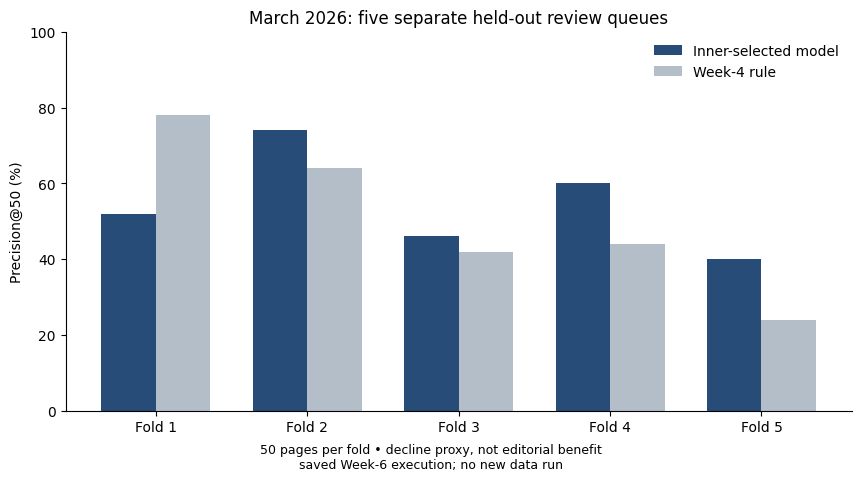

In [8]:
audit_output = OUT / 'w06_saved_audit_metrics.json'
audit_output.write_text(json.dumps(audit_receipt, indent=2, allow_nan=False) + '\n')
plt.rcParams.update({'font.size': 10, 'svg.fonttype': 'none', 'svg.hashsalt': 'w07-playbook'})
fig, ax = plt.subplots(figsize=(8.5, 4.7), layout='constrained')
x = np.arange(len(paired))
ax.bar(x - .18, paired['Inner-selected model'] * 100, width=.36, color='#274c77', label='Inner-selected model')
ax.bar(x + .18, paired['Week-4 baseline rule'] * 100, width=.36, color='#b4bec9', label='Week-4 rule')
ax.set(xticks=x, xticklabels=[f'Fold {i}' for i in paired.index], ylim=(0, 100),
       ylabel='Precision@50 (%)', title='March 2026: five separate held-out review queues')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
fig.supxlabel('50 pages per fold • decline proxy, not editorial benefit\n' + evidence_label, fontsize=9)
precision_path = FIG / 'w07_validation_precision.svg'
fig.savefig(precision_path, metadata={'Date': None})
(OUT / precision_path.name).write_bytes(precision_path.read_bytes())
plt.show()
artifacts = {'saved_audit_receipt': audit_output, 'precision_figure': precision_path}

queue_path = OUT / 'w07_ranked_action_queue.csv'
if queue is not None:
    queue.to_csv(queue_path, index=False, float_format='%.10g')
    roundtrip = pd.read_csv(queue_path)
    assert len(roundtrip) == 250 and list(roundtrip.columns) == list(queue.columns)
    assert roundtrip.groupby('queue_id').size().eq(50).all()
    assert roundtrip.review_status.eq('pending_human_review').all()
    assert not roundtrip.automatic_content_changes_allowed.any()
    artifacts['ranked_queue_local_only'] = queue_path
    counts = queue.groupby('proposed_review_action').size().sort_values()
    fig, ax = plt.subplots(figsize=(8.5, 4.7), layout='constrained')
    ax.barh([v.replace('_', ' ').lower() for v in counts.index], counts, color='#274c77')
    ax.set(xlabel='Pages across five historical queues (250 total)', title='Proposed review actions — all pending human review')
    ax.spines[['top', 'right']].set_visible(False)
    action_path = FIG / 'w07_action_mix.svg'
    fig.savefig(action_path, metadata={'Date': None})
    (OUT / action_path.name).write_bytes(action_path.read_bytes())
    plt.show()
    artifacts['action_mix_figure'] = action_path
else:
    print('Queue CSV and action-mix figure NOT regenerated: approved data are unavailable.')

metrics_receipt = {
    'schema_version': 1,
    'status': 'computed_pending_human_review' if queue is not None else 'pending_approved_data_run',
    'generated_at_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'evidence_label': evidence_label, 'config': CONFIG, 'environment': ENV,
    'source_audit_notebook_sha256': audit_receipt['source_notebook_sha256'],
    'queue_rows_generated_this_run': len(queue) if queue is not None else 0,
    'queue_scope': 'five separate 50-page outer-fold queues; no pooled global top-50 claim',
    'current_fold_metrics': json.loads(current_folds.to_json(orient='records')) if current_folds is not None else None,
    'historical_receipt': str(audit_output.relative_to(ROOT)),
    'inner_selection_current_run': selection_rows if queue is not None else None,
    'reason_code_dictionary': REASONS,
    'cost_scenario': {'minutes_per_review_assumed': 15, 'hours_per_50_reviews_assumed': 12.5,
                      'measured_editorial_value': None, 'measured_revenue_uplift': None},
    'review_rules': review_rules, 'monitoring_plan': json.loads(monitoring.to_json(orient='records')),
    'monitoring_baseline': monitor_baseline,
    'action_counts': {str(k): int(v) for k, v in queue.proposed_review_action.value_counts().items()} if queue is not None else None,
    'decay_refresh_conclusion': 'Short-window impression decline observed; age decay and causal refresh benefit unmeasured.',
    'artifacts': {key: {'path': str(path.relative_to(ROOT)), 'sha256': sha256_file(path)} for key, path in artifacts.items()},
}
(OUT / 'w07_metrics.json').write_text(json.dumps(metrics_receipt, indent=2, allow_nan=False) + '\n')
STATE['exports'] = queue is not None and queue_path.is_file()
print('Wrote aggregate receipts and labeled evidence figure.')
print('Current run status:', metrics_receipt['status'])


## 6. Self-check

An error-free preparation run is not enough: the approved data, actual ranked CSV, and export
checks below must pass. Then read the output, confirm the proposed actions and limitations,
save the executed notebook to `work/notebooks/w07_action_playbook.ipynb`, and commit the current
aggregate JSONs and paper figures. Keep all CSVs and Parquet files out of git.

Submit the repository URL only after that full run and commit:
[github.com/Davidsoooooon/ML-Intern---Briones](https://github.com/Davidsoooooon/ML-Intern---Briones).
The notebook does not assert that a human approved any content action or submitted the card.


In [9]:
ignored = subprocess.run(['git', '-C', str(ROOT), 'check-ignore', '-q',
                          'work/outputs/w07_ranked_action_queue.csv']).returncode == 0
check_rows = [
    ('Saved audit evidence extracted with source hash', bool(audit_receipt['fold_results'])),
    ('Approved March data and client-held-out scores available', STATE['approved_data']),
    ('Five separate ranked queues, 50 pages each', STATE['ranked_queue']),
    ('Queue excludes later outcomes; all decisions await human review', STATE['ranked_queue']),
    ('Intended use, limits, decay/refresh limits and cost assumptions documented', True),
    ('Human-review rules, no-go cases and proposed monitoring triggers documented', True),
    ('Queue CSV regenerated and export round-trip checks passed', STATE['exports']),
    ('Aggregate receipts and reusable evidence figure written', (OUT / 'w07_metrics.json').is_file() and precision_path.is_file()),
    ('Queue CSV remains ignored by git', ignored),
]
display(pd.DataFrame([{'Check': name, 'Status': 'PASS' if passed else 'PENDING'} for name, passed in check_rows]))
if all(passed for _, passed in check_rows):
    print('COMPUTATION COMPLETE — review, save the executed notebook and aggregate artifacts, then submit the repo URL.')
else:
    print('NOT SUBMISSION-READY — preparation is complete, but the approved-data queue run remains pending.')
    print('In Colab, enable the existing HF_TOKEN secret, Run all, then save the executed notebook and generated aggregate files.')
print('Human approval, GitHub writeback of this execution, and portal submission are not asserted by this cell.')


NOT SUBMISSION-READY — preparation is complete, but the approved-data queue run remains pending.
In Colab, enable the existing HF_TOKEN secret, Run all, then save the executed notebook and generated aggregate files.
Human approval, GitHub writeback of this execution, and portal submission are not asserted by this cell.


,Check,Status
0,Saved audit evidence extracted with source hash,PASS
1,Approved March data and client-held-out scores...,PENDING
2,"Five separate ranked queues, 50 pages each",PENDING
3,Queue excludes later outcomes; all decisions a...,PENDING
4,"Intended use, limits, decay/refresh limits and...",PASS
5,"Human-review rules, no-go cases and proposed m...",PASS
6,Queue CSV regenerated and export round-trip ch...,PENDING
7,Aggregate receipts and reusable evidence figur...,PASS
8,Queue CSV remains ignored by git,PASS
